# LeetCode #1306: Jump Game III

https://leetcode.com/problems/jump-game-iii/

## Comparison of Approaches

| Approach | Time Complexity | Space Complexity |
| :--- | :--- | :--- |
| **Brute Force (recursive DFS, no visited set)** | $O(2^n)$ | $O(n)$ |
| **Optimal: BFS / DFS with Visited Set ★** | $O(n)$ | $O(n)$ |

---

## Understanding the Methods

### Brute Force (recursive DFS, no visited set)
Recursively try both jumps from every index without tracking which indices were already visited. Cycles cause exponential revisits even for small arrays.

### Optimal: BFS / DFS with Visited Set ★
Use BFS (or DFS) from the start index. Mark each visited index to avoid revisiting. From index `i`, two neighbors `i + arr[i]` and `i - arr[i]` are enqueued if in-bounds and unvisited. If any dequeued index has value 0, return true. If the queue empties, return false. Each index is processed at most once, giving $O(n)$ time and space.

**Constraints:**
* 1 <= arr.length <= 5 * 10^4
* 0 <= arr[i] < arr.length
* 0 <= start < arr.length

## Solutions
### C#

In [ ]:
// BFS with visited set: explore reachable indices level by level
public class Solution {
    public bool CanReach(int[] arr, int start) {
        int n = arr.Length;
        bool[] visited = new bool[n];
        var queue = new Queue<int>();
        queue.Enqueue(start);
        visited[start] = true;

        while (queue.Count > 0) {
            int idx = queue.Dequeue();
            // A zero value means we can reach a value-0 index — success
            if (arr[idx] == 0) return true;

            // Try jumping forward and backward by arr[idx] steps
            foreach (int next in new[] { idx + arr[idx], idx - arr[idx] }) {
                if (next >= 0 && next < n && !visited[next]) {
                    visited[next] = true;
                    queue.Enqueue(next);
                }
            }
        }
        return false;
    }
}

### Python

In [ ]:
# BFS with visited set: explore reachable indices level by level
from typing import List
from collections import deque

class Solution:
    def canReach(self, arr: List[int], start: int) -> bool:
        n = len(arr)
        visited = [False] * n
        queue = deque([start])
        visited[start] = True

        while queue:
            idx = queue.popleft()
            # Reaching an index whose value is 0 satisfies the goal
            if arr[idx] == 0:
                return True
            # Jump forward and backward by arr[idx]
            for next_idx in (idx + arr[idx], idx - arr[idx]):
                if 0 <= next_idx < n and not visited[next_idx]:
                    visited[next_idx] = True
                    queue.append(next_idx)

        return False

### Go

In [ ]:
// BFS with visited set: explore reachable indices level by level
package main

func canReach(arr []int, start int) bool {
    n := len(arr)
    visited := make([]bool, n)
    queue := []int{start}
    visited[start] = true

    for len(queue) > 0 {
        idx := queue[0]
        queue = queue[1:]
        // An index with value 0 is a winning position
        if arr[idx] == 0 {
            return true
        }
        // Try both possible jumps from this index
        for _, next := range []int{idx + arr[idx], idx - arr[idx]} {
            if next >= 0 && next < n && !visited[next] {
                visited[next] = true
                queue = append(queue, next)
            }
        }
    }
    return false
}

### Rust

In [ ]:
// BFS with visited set: explore reachable indices level by level
use std::collections::VecDeque;

impl Solution {
    pub fn can_reach(arr: Vec<i32>, start: i32) -> bool {
        let n = arr.len();
        let mut visited = vec![false; n];
        let mut queue = VecDeque::new();
        let start = start as usize;
        queue.push_back(start);
        visited[start] = true;

        while let Some(idx) = queue.pop_front() {
            // A zero value at this index means we succeeded
            if arr[idx] == 0 {
                return true;
            }
            // Explore both jump directions
            let jump = arr[idx] as usize;
            if idx + jump < n && !visited[idx + jump] {
                visited[idx + jump] = true;
                queue.push_back(idx + jump);
            }
            if idx >= jump && !visited[idx - jump] {
                visited[idx - jump] = true;
                queue.push_back(idx - jump);
            }
        }
        false
    }
}

## Example Scenarios

The array is really a **graph**: index $i$ has directed edges to $i + \text{arr}[i]$ and $i - \text{arr}[i]$ whenever those stay in bounds. The question is only whether any index holding 0 lies in the connected component reachable from `start`. BFS with a visited array answers that in $O(n)$; without the visited array the same cycles get re-explored exponentially.

### 1. Common Case — A Short Path to a Zero

**Input:** `arr = [4,2,3,0,3,1,2]`, `start = 5`

BFS dequeues 5 (value 1) and enqueues $5+1=6$ and $5-1=4$. Index 6 (value 2) offers only 8, out of bounds. Index 4 (value 3) reaches 1 ($7$ is out of bounds). Index 1 (value 2) reaches 3, and `arr[3] == 0`. **Returns `true`** after visiting 5 of the 7 indices.

### 2. Slightly Complex — A Different Start, the Same Zero

**Input:** `arr = [4,2,3,0,3,1,2]`, `start = 0`

Same array, different entry point. Index 0 (value 4) can only go forward to 4, since $-4$ is out of bounds. From 4 the walk is $4 \to 1 \to 3$, exactly as before. **Returns `true`**, but this time only 4 indices are ever visited — reachability depends entirely on where you enter the graph, which is why the whole problem is a graph-search question rather than an array scan.

### 3. Edge Case: Time Factor — A Zero That Exists but Cannot Be Reached

**Input:** `arr = [3,0,2,1,2]`, `start = 2`

`arr[1] = 0`, so a zero *does* exist — but index 1 is in a different component. From 2 the reachable set is $\{2, 0, 4, 3\}$: $2 \to \{0,4\}$, $0 \to 3$, $4 \to$ nothing new, $3 \to \{4,2\}$ both already seen. The queue drains with index 1 never entering it. **Returns `false`.** The decoy is the point: the presence of a 0 in the array proves nothing.

### 4. Edge Case: Space Factor — Full Traversal of a 50 000-Index Chain

**Input:** `arr = [1,1,\ldots,1,0]` (50 000 elements), `start = 0`

Every index has value 1, so the graph is a path and BFS walks it end to end, enqueuing each index exactly once before finding the 0 at index $n-1$. The visited array is $n$ booleans and the queue holds at most a handful at a time, so space is $O(n)$ — dominated by `visited`, not by the frontier. This is the maximum work the constraints permit.

### 5. Almost-Impossible but Plausible — The Start Index Is Itself a Zero

**Input:** `arr = [0]`, `start = 0`

A single-element array where the answer is decided before any jump is attempted: the first dequeue sees `arr[0] == 0` and returns `true`. This is worth checking explicitly because an implementation that tests the value *after* computing jumps — or that only checks neighbours as they are enqueued — would compute $0 \pm 0 = 0$, find it already visited, drain the queue, and wrongly return `false`.


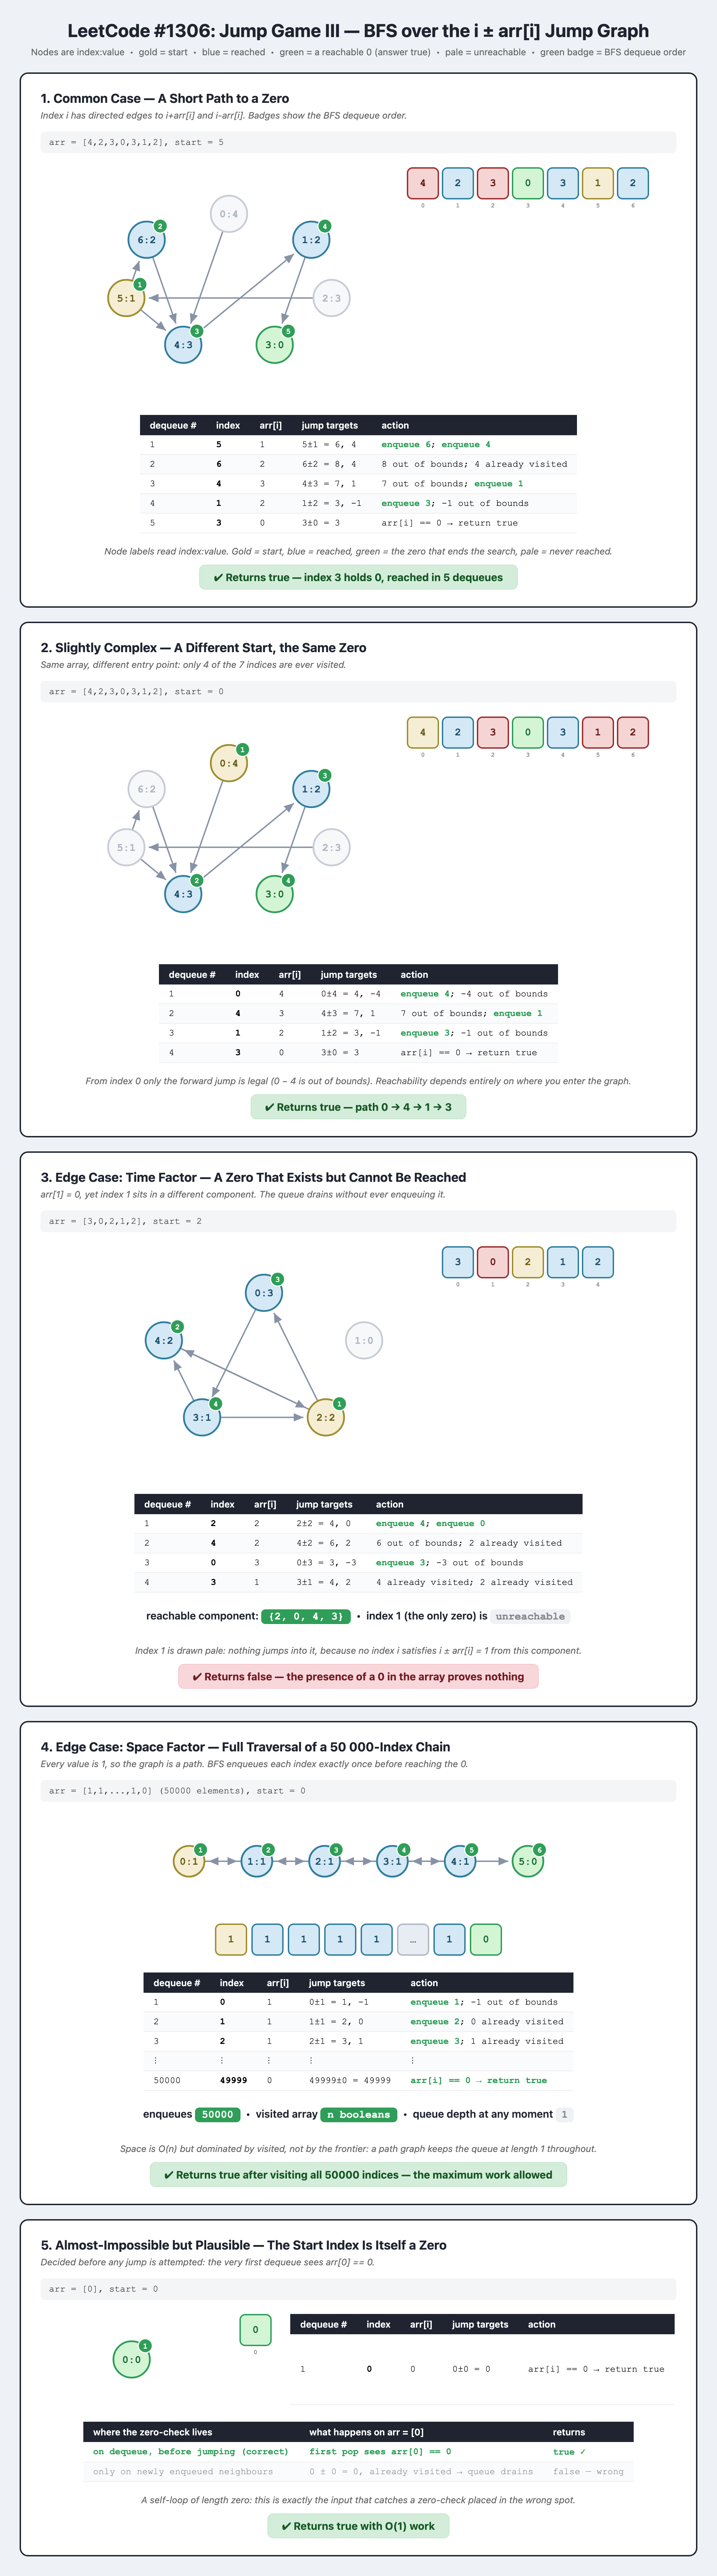